In [ ]:
 # Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.model_selection import KFold, cross_validate, cross_val_predict

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

In [ ]:
# Load data
base_path = "/content/drive/MyDrive/ML_Assignment/"

train_path = base_path + "Results/Outputs/final_preprocessed_train.csv"
test_path = base_path + "Results/Outputs/final_preprocessed_test.csv"

# Preserve meaningful "None" categories; treat empty cells as missing
train_df = pd.read_csv(
    train_path,
    keep_default_na=False,
    na_values=[""]
)

test_df = pd.read_csv(
    test_path,
    keep_default_na=False,
    na_values=[""]
)

# Restore categorical feature types
for df in [train_df, test_df]:
    for col in ["MSSubClass", "MoSold"]:
        if col in df.columns:
            df[col] = df[col].astype(str)

# Separate features and target
X = train_df.drop(columns=["SalePrice"])
y = train_df["SalePrice"]

test_X = test_df.copy()

In [ ]:
# Log transform target
y_log = np.log1p(y)

# Identify feature types
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Training shape:", X.shape)
print("Test shape:", test_X.shape)
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Training shape: (1460, 75)
Test shape: (1459, 75)
Numerical features: 34
Categorical features: 41


Preprocessing Pipeline

In [ ]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

Cross Validation

In [ ]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2"
}

Create gradient boosting model

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

print("Gradinet Boosting pipeline created.")

Gradinet Boosting pipeline created.


Train and Evaluate

In [ ]:
gb_cv = cross_validate(
    gb_pipeline,
    X,
    y_log,
    cv=kf,
    scoring=scoring,
    return_train_score = True
)

Gradient Boosting Results

In [ ]:
gb_results = pd.DataFrame({
    "Fold": range(1, 6),

    "Train_RMSE": -gb_cv["train_rmse"],
    "Validation_RMSE": -gb_cv["test_rmse"],

    "Train_MAE": -gb_cv["train_mae"],
    "Validation_MAE": -gb_cv["test_mae"],

    "Train_R2": gb_cv["train_r2"],
    "Validation_R2": gb_cv["test_r2"]
})

gb_results.round(4)

,Fold,Train_RMSE,Validation_RMSE,Train_MAE,Validation_MAE,Train_R2,Validation_R2
0,1,0.0688,0.1394,0.0513,0.0907,0.9690,0.8959
1,2,0.0695,0.1138,0.0523,0.0789,0.9698,0.9167
2,3,0.0681,0.1663,0.0512,0.0970,0.9717,0.8036
3,4,0.0707,0.1309,0.0528,0.0906,0.9678,0.9031
4,5,0.0698,0.1244,0.0531,0.0821,0.9705,0.8860


Mean Performance

In [ ]:
print("GRADIENT BOOSTING - 5 FOLD CV")
print("--------------------------------------")

print("Mean Validation RMSE:",
      gb_results["Validation_RMSE"].mean())

print("Mean Validation MAE:",
      gb_results["Validation_MAE"].mean())

print("Mean Validation R²:",
      gb_results["Validation_R2"].mean())

print("--------------------------------------")

print("RMSE Standard Deviation:",
      gb_results["Validation_RMSE"].std())

print("MAE Standard Deviation:",
      gb_results["Validation_MAE"].std())

print("R² Standard Deviation:",
      gb_results["Validation_R2"].std())

GRADIENT BOOSTING - 5 FOLD CV
--------------------------------------
Mean Validation RMSE: 0.13494738671761908
Mean Validation MAE: 0.08784263422938683
Mean Validation R²: 0.8810652219082582
--------------------------------------
RMSE Standard Deviation: 0.01988412075307306
MAE Standard Deviation: 0.007308573526589383
R² Standard Deviation: 0.04472859730148743


RMSE graph

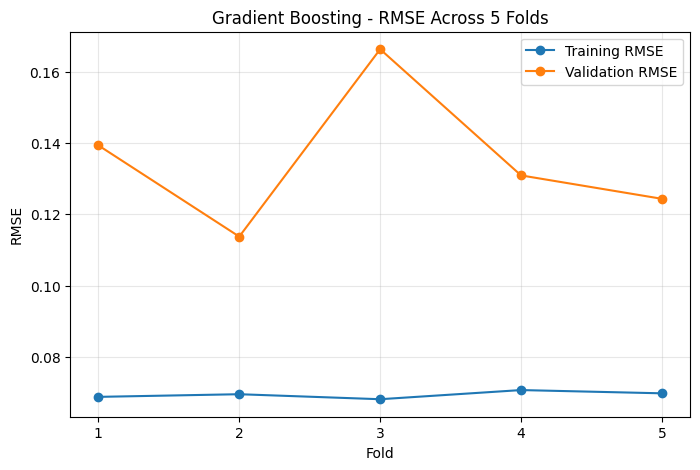

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    gb_results["Fold"],
    gb_results["Train_RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    gb_results["Fold"],
    gb_results["Validation_RMSE"],
    marker="o",
    label="Validation RMSE"
)

plt.xlabel("Fold")
plt.ylabel("RMSE")
plt.title("Gradient Boosting - RMSE Across 5 Folds")
plt.xticks(range(1, 6))
plt.legend()
plt.grid(alpha=0.3)

plt.show()

Predictions

In [ ]:
gb_pred = cross_val_predict(
    gb_pipeline,
    X,
    y_log,
    cv=kf
)

Actual vs predicted

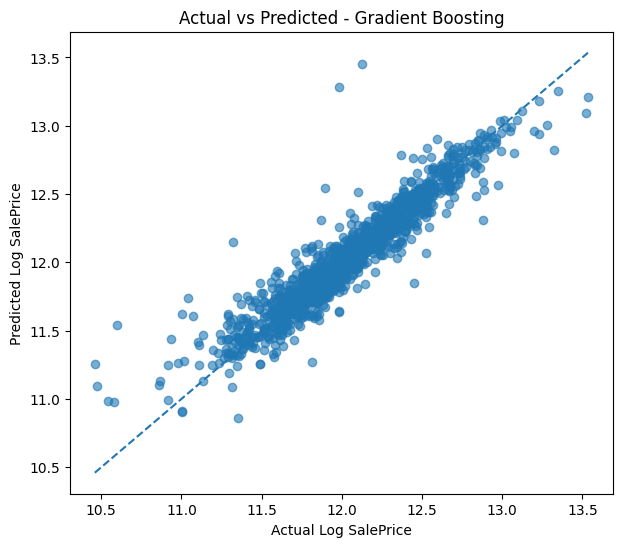

In [ ]:
plt.figure(figsize=(7, 6))

plt.scatter(y_log, gb_pred, alpha=0.6)

min_value = min(y_log.min(), gb_pred.min())
max_value = max(y_log.max(), gb_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Log SalePrice")
plt.ylabel("Predicted Log SalePrice")
plt.title("Actual vs Predicted - Gradient Boosting")

plt.show()

Residuals

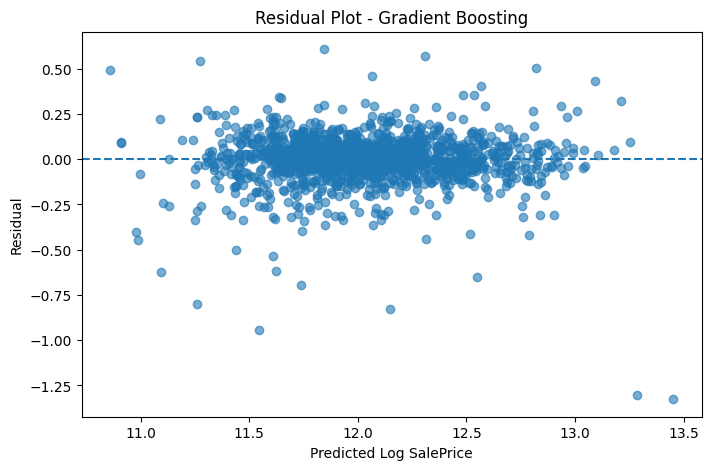

In [ ]:
gb_residuals = y_log - gb_pred

plt.figure(figsize=(8, 5))

plt.scatter(gb_pred, gb_residuals, alpha=0.6)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Log SalePrice")
plt.ylabel("Residual")
plt.title("Residual Plot - Gradient Boosting")

plt.show()

Residual Distribution

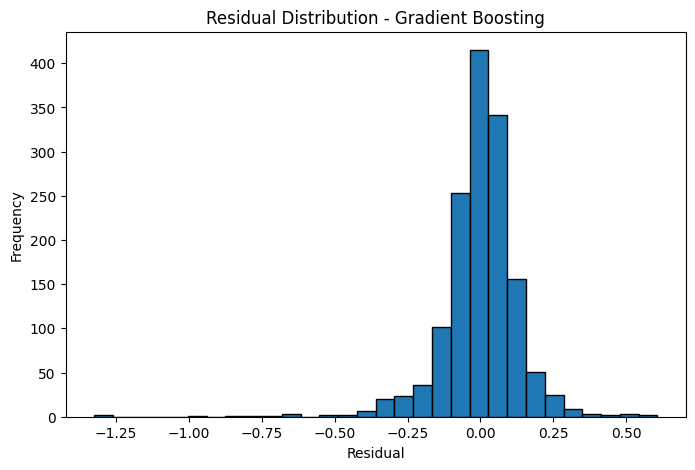

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    gb_residuals,
    bins=30,
    edgecolor="black"
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Residual Distribution - Gradient Boosting")

plt.show()

Save gradient boosting results

In [ ]:
output_path = base_path + "Results/Outputs/"

gb_results.to_csv(
    output_path + "gradient_boosting_results.csv",
    index=False
)

print("Gradient Boosting results saved successfully.")

Gradient Boosting results saved successfully.


Hyperparameter Tuning — Gradient Boosting

In [ ]:
# ============================================================
# SECTION 1: IMPORT LIBRARIES AND LOAD DATA
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_val_score

# Project folder
base_path = "/content/drive/MyDrive/ML_Assignment/"

# Load preprocessed training dataset
train_path = base_path + "Results/Outputs/final_preprocessed_train.csv"

# Preserve meaningful "None" categories
train_df = pd.read_csv(
    train_path,
    keep_default_na=False,
    na_values=[""]
)

# Separate features and target
X = train_df.drop(columns=["SalePrice"])
y = train_df["SalePrice"]

# Log-transform target
y_log = np.log1p(y)

print("Training features:", X.shape)
print("Target:", y_log.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training features: (1460, 75)
Target: (1460,)


In [ ]:
# ============================================================
# SECTION 2: CREATE PREPROCESSING PIPELINE
# ============================================================

# Restore categorical feature types
for col in ["MSSubClass", "MoSold"]:
    if col in X.columns:
        X[col] = X[col].astype(str)

# Identify feature types
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine transformations
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
# ============================================================
# SECTION 3: CREATE ORIGINAL GRADIENT BOOSTING PIPELINE
# ============================================================

gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),

    ("model", GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

print("Gradient Boosting pipeline created successfully!")

Gradient Boosting pipeline created successfully!


In [ ]:
# ============================================================
# SECTION 4: DEFINE CROSS-VALIDATION
# ============================================================

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-Fold Cross-Validation configured!")

5-Fold Cross-Validation configured!


In [ ]:
# ============================================================
# SECTION 5: HYPERPARAMETER SEARCH SPACE
# ============================================================

param_grid = {

    # Number of boosting trees
    "model__n_estimators": [200, 300, 400, 500],

    # Learning rate
    "model__learning_rate": [0.03, 0.05, 0.1],

    # Maximum tree depth
    "model__max_depth": [2, 3, 4],

    # Minimum samples required at a leaf node
    "model__min_samples_leaf": [1, 2, 4],

    # Fraction of samples used for each tree
    "model__subsample": [0.8, 1.0]
}

print("Hyperparameter search space defined!")

Hyperparameter search space defined!


In [ ]:
# ============================================================
# SECTION 6: RANDOMIZED SEARCH HYPERPARAMETER TUNING
# ============================================================

random_search_gb = RandomizedSearchCV(

    # Gradient Boosting pipeline
    estimator=gb_pipeline,

    # Hyperparameter combinations
    param_distributions=param_grid,

    # Test 12 randomly selected combinations
    n_iter=12,

    # Minimize RMSE
    scoring="neg_root_mean_squared_error",

    # Use the same 5 folds
    cv=kf,

    # Reproducibility
    random_state=42,

    # Parallel processing
    n_jobs=-1,

    # Display progress
    verbose=1,

    # Refit best model
    refit=True,

    # Raise fitting errors
    error_score="raise"
)

# Start tuning
random_search_gb.fit(X, y_log)

print("Gradient Boosting hyperparameter tuning completed!")

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Gradient Boosting hyperparameter tuning completed!


In [ ]:
# ============================================================
# SECTION 7: BEST HYPERPARAMETERS
# ============================================================

print("BEST GRADIENT BOOSTING PARAMETERS")
print("--------------------------------------")

for parameter, value in random_search_gb.best_params_.items():
    print(parameter, ":", value)

print("--------------------------------------")

print(
    "Best CV RMSE:",
    round(-random_search_gb.best_score_, 4)
)

BEST GRADIENT BOOSTING PARAMETERS
--------------------------------------
model__subsample : 0.8
model__n_estimators : 500
model__min_samples_leaf : 1
model__max_depth : 3
model__learning_rate : 0.03
--------------------------------------
Best CV RMSE: 0.1306


In [ ]:
# ============================================================
# SECTION 8: HYPERPARAMETER TUNING RESULTS
# ============================================================

gb_tuning_results = pd.DataFrame(
    random_search_gb.cv_results_
)

# Convert negative RMSE to positive
gb_tuning_results["Mean_RMSE"] = (
    -gb_tuning_results["mean_test_score"]
)

gb_tuning_results["RMSE_SD"] = (
    gb_tuning_results["std_test_score"]
)

# Sort by lowest RMSE
gb_tuning_results = gb_tuning_results.sort_values(
    by="Mean_RMSE",
    ascending=True
)

display(
    gb_tuning_results[
        [
            "params",
            "Mean_RMSE",
            "RMSE_SD",
            "rank_test_score"
        ]
    ].round(4)
)

,params,Mean_RMSE,RMSE_SD,rank_test_score
11,"{'model__subsample': 0.8, 'model__n_estimators...",0.1306,0.0180,1
8,"{'model__subsample': 1.0, 'model__n_estimators...",0.1334,0.0173,2
0,"{'model__subsample': 1.0, 'model__n_estimators...",0.1337,0.0175,3
5,"{'model__subsample': 1.0, 'model__n_estimators...",0.1346,0.0186,4
2,"{'model__subsample': 0.8, 'model__n_estimators...",0.1352,0.0202,5
6,"{'model__subsample': 0.8, 'model__n_estimators...",0.1352,0.0199,6
9,"{'model__subsample': 1.0, 'model__n_estimators...",0.1357,0.0205,7
10,"{'model__subsample': 1.0, 'model__n_estimators...",0.1358,0.0201,8
4,"{'model__subsample': 1.0, 'model__n_estimators...",0.1359,0.0203,9
1,"{'model__subsample': 1.0, 'model__n_estimators...",0.1379,0.0193,10


In [30]:
# ============================================================
# SECTION 9: INITIAL VS TUNED GRADIENT BOOSTING
# ============================================================

# Evaluate original Gradient Boosting model
initial_scores = cross_val_score(
    gb_pipeline,
    X,
    y_log,
    cv=kf,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

initial_rmse = -initial_scores.mean()

# Best score found by RandomizedSearchCV
tuned_rmse = -random_search_gb.best_score_

# Create comparison table
gb_tuning_comparison = pd.DataFrame({
    "Model": [
        "Initial Gradient Boosting",
        "Tuned Gradient Boosting"
    ],
    "CV_RMSE": [
        initial_rmse,
        tuned_rmse
    ]
})

display(gb_tuning_comparison.round(4))

,Model,CV_RMSE
0,Initial Gradient Boosting,0.1349
1,Tuned Gradient Boosting,0.1306


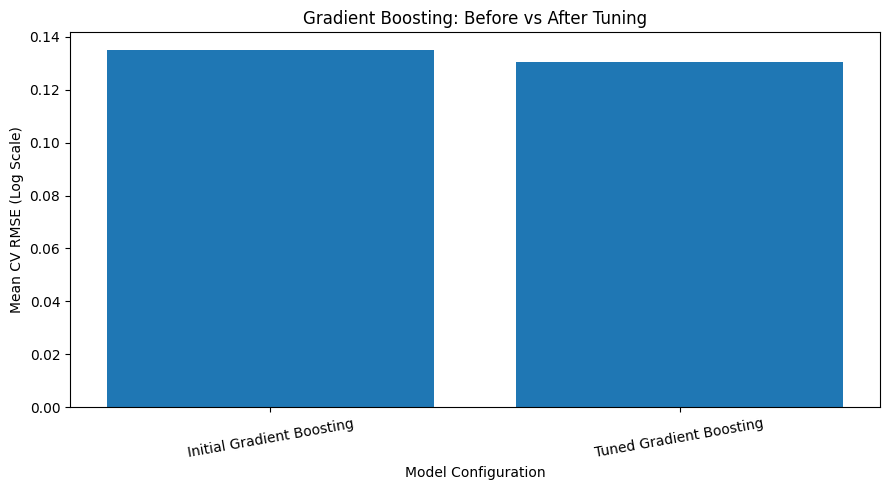

In [31]:
 # ============================================================
# SECTION 10: VISUALIZE INITIAL VS TUNED
# ============================================================

plt.figure(figsize=(9, 5))

plt.bar(
    gb_tuning_comparison["Model"],
    gb_tuning_comparison["CV_RMSE"]
)

plt.xlabel("Model Configuration")
plt.ylabel("Mean CV RMSE (Log Scale)")
plt.title("Gradient Boosting: Before vs After Tuning")

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# SECTION 11: COMPARE CONFIGURATIONS
# ============================================================

print("Initial RMSE:", round(initial_rmse, 4))
print("Tuned search RMSE:", round(tuned_rmse, 4))

if initial_rmse <= tuned_rmse:
    print("\nInitial Gradient Boosting performed better.")
    print("Keep the original configuration as the current candidate.")
else:
    print("\nThe tuned configuration is promising.")
    print("Further independent evaluation is needed.")

Initial RMSE: 0.1349
Tuned search RMSE: 0.1306

The tuned configuration is promising.
Further independent evaluation is needed.


In [ ]:
# ============================================================
# SECTION 12: SAVE HYPERPARAMETER TUNING RESULTS
# ============================================================

output_path = base_path + "Results/Outputs/"

os.makedirs(output_path, exist_ok=True)

# Save all tested combinations
gb_tuning_results.to_csv(
    output_path + "gradient_boosting_tuning_results.csv",
    index=False
)

# Save initial vs tuned comparison
gb_tuning_comparison.to_csv(
    output_path + "gradient_boosting_tuning_comparison.csv",
    index=False
)

print("Gradient Boosting tuning results saved successfully!")

Gradient Boosting tuning results saved successfully!


In [ ]:
# ============================================================
# SECTION 13: COMPARE INITIAL VS TUNED GRADIENT BOOSTING
# ============================================================

# Initial Gradient Boosting RMSE
initial_rmse = -initial_scores.mean()

# Best RMSE found during tuning
tuned_rmse = -random_search_gb.best_score_

comparison = pd.DataFrame({
    "Model": [
        "Initial Gradient Boosting",
        "Tuned Gradient Boosting"
    ],
    "CV_RMSE": [
        initial_rmse,
        tuned_rmse
    ]
})

display(comparison.round(4))

# Preliminary interpretation
if tuned_rmse < initial_rmse:
    print("Tuning found a configuration with lower CV RMSE.")
else:
    print("The initial configuration achieved lower CV RMSE.")

,Model,CV_RMSE
0,Initial Gradient Boosting,0.1349
1,Tuned Gradient Boosting,0.1306


Tuning found a configuration with lower CV RMSE.


In [ ]:
# ============================================================
# SECTION 14: COMPARE PROMISING MODELS
# ============================================================

xgb_results = pd.read_csv(
    output_path + "xgboost_results.csv"
)

xgb_initial_rmse = xgb_results["Validation_RMSE"].mean()

final_candidates = pd.DataFrame({
    "Model": [
        "Initial XGBoost",
        "Initial Gradient Boosting",
        "Tuned Gradient Boosting"
    ],
    "CV_RMSE": [
        xgb_initial_rmse,
        initial_rmse,
        tuned_rmse
    ]
})

final_candidates = final_candidates.sort_values("CV_RMSE")

display(final_candidates.round(4))

,Model,CV_RMSE
0,Initial XGBoost,0.1291
2,Tuned Gradient Boosting,0.1306
1,Initial Gradient Boosting,0.1349
